# **Import**

In [1]:
import os
import numpy as np
import cv2
from glob import glob
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, BatchNormalization, Activation, MaxPool2D, Conv2DTranspose, Concatenate, Input
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger
from google.colab import drive
import matplotlib.pyplot as plt
import pandas as pd

# Seeding

In [2]:
os.environ["PYTHONHASHSEED"] = str(42)
np.random.seed(42)
tf.random.set_seed(42)

# Hyperparameters

In [28]:
batch_size = 2
lr = 1e-4 ## 0.0001
epochs = 20
height = 1312
width = 800

# Path

In [29]:
from google.colab import drive
drive.mount('/content/drive')

In [30]:
!unzip "/content/drive_2/MyDrive/CALC-TRAINING-png.zip" -d "/content/drive_2/MyDrive/MammographyProject"

unzip:  cannot find or open /content/drive_2/MyDrive/CALC-TRAINING-png.zip, /content/drive_2/MyDrive/CALC-TRAINING-png.zip.zip or /content/drive_2/MyDrive/CALC-TRAINING-png.zip.ZIP.


In [31]:
dataset_path = os.path.join("/content/drive/MyDrive/MammographyProject", "CALC-TRAINING-png")

files_dir = os.path.join(dataset_path, "files")
model_file = os.path.join(files_dir, "emre/MAMMOGRAPHY_Bitirme_AEM_MFO.h5")
log_file = os.path.join(files_dir, "emre/MAMMOGRAPHY_Bitirme_AEM_MFO.csv")

# Creating Folder

In [32]:
def create_dir(path):
  if not os.path.exists(path):
    os.makedirs(path)

In [33]:
create_dir(files_dir)

# Building UNET

### Conv Block

In [34]:
def conv_block(inputs, num_filters):
  x = Conv2D(num_filters, 3, padding="same")(inputs)
  x = BatchNormalization()(x)
  x = Activation("relu")(x)

  x = Conv2D(num_filters, 3, padding="same")(x)
  x = BatchNormalization()(x)
  x = Activation("relu")(x)

  return x

### Encoder Block

In [35]:
def encoder_block(inputs, num_filters):
  x = conv_block(inputs, num_filters)
  p = MaxPool2D((2, 2))(x)
  return x, p

### Decoder Block

In [36]:
def decoder_block(inputs, skip, num_filters):
  x = Conv2DTranspose(num_filters, (2, 2), strides = 2, padding = "same")(inputs)
  x = Concatenate()([x, skip])
  x = conv_block(x, num_filters)
  return x

### UNET

In [37]:
def build_unet(input_shape):
  inputs = Input(input_shape)

  """ Encoder """
  s1, p1 = encoder_block(inputs, 64)
  s2, p2 = encoder_block(p1, 128)
  s3, p3 = encoder_block(p2, 256)
  s4, p4 = encoder_block(p3, 512)

  """ Bridge """
  b1 = conv_block(p4, 1024)

  """ Decoder """
  d1 = decoder_block(b1, s4, 512)
  d2 = decoder_block(d1, s3, 256)
  d3 = decoder_block(d2, s2, 128)
  d4 = decoder_block(d3, s1, 64)

  outputs = Conv2D(1, 1, padding = "same", activation = "sigmoid")(d4)

  model = Model(inputs, outputs, name = "UNET")
  return model


# Dataset Pipeline

### Loading the training and validation dataset

In [38]:
def load_data(path):
  train_x = sorted(glob(os.path.join(path, "train", "images", "*")))
  train_y = sorted(glob(os.path.join(path, "train", "masks", "*")))

  valid_x = sorted(glob(os.path.join(path, "valid", "images", "*")))
  valid_y = sorted(glob(os.path.join(path, "valid", "masks", "*")))

  return (train_x, train_y), (valid_x, valid_y)

### Reading Images

In [39]:
def read_image(path):
  if(isinstance(path, str) == False):
    path = path.decode()
  x = cv2.imread(path, cv2.IMREAD_COLOR)
  resized = cv2.resize(x, (width, height), interpolation = cv2.INTER_AREA)
  resized = resized/255.0
  return resized

In [ ]:
x = read_image('/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/train/images/Calc-Training_P_00621_LEFT_CC.png') #its work without path = path.decode()
print(x.shape)

### Reading Mask

In [41]:
def read_mask(path):
  if(isinstance(path, str) == False):
    path = path.decode()
  x = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
  resized = cv2.resize(x, (width, height), interpolation = cv2.INTER_AREA)
  resized = resized/255.0
  resized = np.expand_dims(resized, axis=-1)
  return resized

In [ ]:
x = read_mask('/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/train/images/Calc-Training_P_00621_LEFT_CC.png') #its work without path = path.decode()
print(x.shape)

### tf.data pipline

In [43]:
def tf_parse(x, y):
  def _parse(x, y):
    x = read_image(x)
    y = read_mask(y)
    return x, y

  x, y = tf.numpy_function(_parse, [x, y], [tf.float64, tf.float64])
  x.set_shape([height, width, 3])
  y.set_shape([height, width, 1])
  return x, y

In [44]:
def tf_dataset(x, y, batch=8):
  dataset = tf.data.Dataset.from_tensor_slices((x, y))
  dataset = dataset.map(tf_parse, num_parallel_calls=tf.data.AUTOTUNE)
  dataset = dataset.batch(batch)
  dataset = dataset.prefetch(tf.data.AUTOTUNE)
  return dataset

### Training

In [45]:
(train_x, train_y), (valid_x, valid_y) = load_data(dataset_path)
print(f"Train: {len(train_x)} - {len(train_y)}")
print(f"Valid: {len(valid_x)} - {len(valid_y)}")

Train: 860 - 860
Valid: 367 - 367


In [46]:
train_dataset = tf_dataset(train_x, train_y, batch=batch_size)
valid_dataset = tf_dataset(valid_x, valid_y, batch=batch_size)

In [47]:
#for x, y in train_dataset:
#  print(x.shape, y.shape)

In [48]:
input_shape = (height, width, 3)
model = build_unet(input_shape)

### Loading Weights
Use this line for only resume the training

In [49]:
#model.load_weights(model_file)

In [ ]:
model.summary()

In [51]:
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, CSVLogger, EarlyStopping

# IoU metric
#class MeanIoU(tf.keras.metrics.MeanIoU):
#    def __init__(self, num_classes, name=None, dtype=None):
#        super(MeanIoU, self).__init__(num_classes=num_classes, name=name, dtype=dtype)
#
## F1 Score metric
#def f1_score(y_true, y_pred):
#    y_true = tf.keras.backend.flatten(y_true)
#    y_pred = tf.keras.backend.flatten(y_pred)
#    tp = tf.keras.backend.sum(y_true * y_pred)
#    fp = tf.keras.backend.sum((1 - y_true) * y_pred)
#    fn = tf.keras.backend.sum(y_true * (1 - y_pred))
#    precision = tp / (tp + fp + tf.keras.backend.epsilon())
#    recall = tp / (tp + fn + tf.keras.backend.epsilon())
#    f1 = 2 * (precision * recall) / (precision + recall + tf.keras.backend.epsilon())
#    return f1

# Model compile
opt = tf.keras.optimizers.Adam(learning_rate=lr)
model.compile(loss="binary_crossentropy", optimizer=opt, metrics=["accuracy"])



In [54]:
callbacks = [
    ModelCheckpoint(model_file, verbose=1, save_best_only=True, save_weights_only=True),
    ReduceLROnPlateau(   monitor='val_loss',
    factor = 0.2,
    patience = 2,
    min_delt = 1e-7,
    cooldown = 0,
    verbose = 1),
    CSVLogger(log_file),
    EarlyStopping( monitor='val_loss',
    patience=5,
    min_delta=1e-7,
    restore_best_weights=True,)
]

In [ ]:
model.load_weights('best_model.h5')

In [ ]:
model.fit(
    train_dataset,
    validation_data=valid_dataset,
    epochs=epochs,
    callbacks=callbacks
)

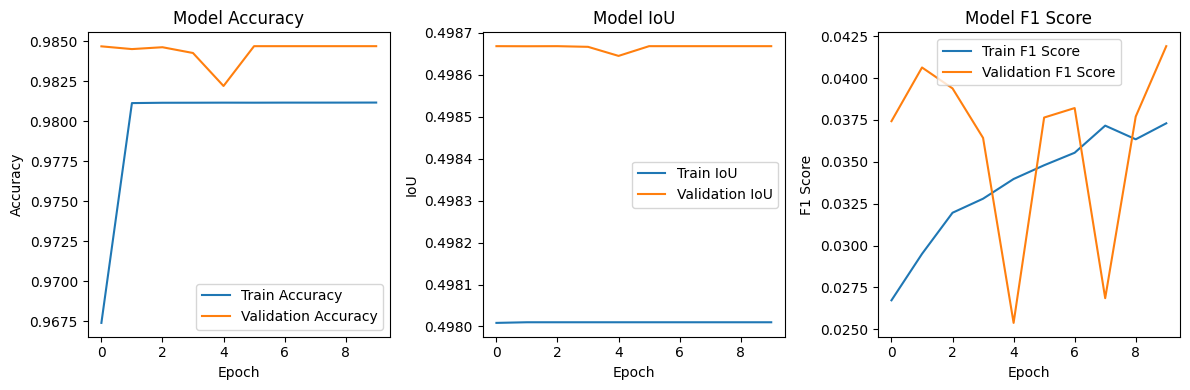

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# CSV dosyasını oku
history = pd.read_csv(log_file)

# Accuracy plot
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(history['accuracy'])
plt.plot(history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train Accuracy', 'Validation Accuracy'])

# IoU plot
plt.subplot(1, 3, 2)
plt.plot(history['mean_io_u'])
plt.plot(history['val_mean_io_u'])
plt.title('Model IoU')
plt.ylabel('IoU')
plt.xlabel('Epoch')
plt.legend(['Train IoU', 'Validation IoU'])

# F1-Score plot
plt.subplot(1, 3, 3)
plt.plot(history['f1_score'])
plt.plot(history['val_f1_score'])
plt.title('Model F1 Score')
plt.ylabel('F1 Score')
plt.xlabel('Epoch')
plt.legend(['Train F1 Score', 'Validation F1 Score'])

plt.tight_layout()
plt.show()


In [ ]:
print("Micro Precision: %f "%micro_precision)
print("Micro Recall: %f "%micro_recall)
print("Micro F1: %f"%micro_f1)
#print("AUC Score: %f"%roc_auc_score(y_true, y_pred, average='micro'))
print("\n")

print("Acuracy: %f "%accuracy_score(post_test.classes, y_pred))
print("Macro Precision: %f "%macro_precision)
print("Macro Recall: %f "%macro_recall)
print("Macro F1: %f"%macro_f1)
#print("AUC Score: %f"%roc_auc_score(testdata.classes, y_pred, average='macro'))
print("\n")

print("Weighted Precision: %f "%weighted_precision)
print("Weighted Recall: %f "%weighted_recall)
print("Weighted F1: %f"%weighted_f1)
#print("ROC_AUC Score: %f"%roc_auc_score(post_test.classes, y_pred, average='weighted'))

Predict

In [ ]:
import os
import time
import numpy as np
import cv2
from glob import glob
from tqdm import tqdm
from google.colab import drive
import tensorflow as tf
from matplotlib import pyplot as plt

In [ ]:
os.environ["PYTHONHASHSEED"] = str(42)
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
height = 1312
width = 800

In [ ]:
save_path = os.path.join("/content/drive_2/MyDrive/MammographyProject", "prediction")
model_path = os.path.join("/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/files", "MAMMOGRAPHY_Bitirme_AEM_MFO.h5")

In [ ]:
def create_dir(path):
  if not os.path.exists(path):
    os.makedirs(path)

In [ ]:
create_dir(save_path)

Load Model

In [ ]:
import tensorflow as tf
from keras import backend as K
from keras.utils import custom_object_scope
import os

def f1_score(y_true, y_pred):
    def recall(y_true, y_pred):
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        possible_positives = K.sum(K.round(K.clip(y_true, 0, 1)))
        recall = true_positives / (possible_positives + K.epsilon())
        return recall

    def precision(y_true, y_pred):
        true_positives = K.sum(K.round(K.clip(y_true * y_pred, 0, 1)))
        predicted_positives = K.sum(K.round(K.clip(y_pred, 0, 1)))
        precision = true_positives / (predicted_positives + K.epsilon())
        return precision

    precision = precision(y_true, y_pred)
    recall = recall(y_true, y_pred)
    f1 = 2 * ((precision * recall) / (precision + recall + K.epsilon()))
    return f1

model_path = os.path.join("/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/files", "MAMMOGRAPHY_Bitirme_AEM_MFO.h5")

with custom_object_scope({'f1_score': f1_score}):
    model = tf.keras.models.load_model(model_path)


In [ ]:
model.summary()

In [ ]:
test_x = sorted(glob(os.path.join(dataset_path, "images", "*")))
mask_x = sorted(glob(os.path.join(dataset_path, "masks", "*")))
print(f"Test Images: {len(test_x)}")
print(f"Mask Images: {len(mask_x)}")

Test Images: 10
Mask Images: 10


In [ ]:
test_x

['/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02475_LEFT_CC.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02475_LEFT_MLO.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02489_RIGHT_CC.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02489_RIGHT_MLO.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02508_LEFT_CC.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02566_RIGHT_MLO.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02572_LEFT_CC.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02572_LEFT_MLO.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/images/Calc-Training_P_02584_LEFT_CC.png',
 '/content/drive_2/MyDrive/Mam

In [ ]:
mask_x

['/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02475_LEFT_CC_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02475_LEFT_MLO_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02489_RIGHT_CC_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02489_RIGHT_MLO_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02508_LEFT_CC_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02566_RIGHT_MLO_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02572_LEFT_CC_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02572_LEFT_MLO_ROI.png',
 '/content/drive_2/MyDrive/MammographyProject/CALC-TRAINING-png/masks/Calc-Training_P_02584_LEFT_CC_ROI.png',
 '/

In [ ]:
time_taken = []

for x in tqdm(test_x):
  name = x.split("/")[-1]

  x = cv2.imread(x, cv2.IMREAD_COLOR)
  x_org_height = x.shape[0]
  x_org_width = x.shape[1]
  x = cv2.resize(x, (width, height), interpolation = cv2.INTER_AREA)
  x = x/255.0
  x = np.expand_dims(x, axis=0)

  start_time = time.time()
  p = model.predict(x)[0]
  total_time = time.time() - start_time
  time_taken.append(total_time)
  p = p * 255
  thr, p = cv2.threshold(p, 127, 255, cv2.THRESH_BINARY);
  p = cv2.resize(p, (x_org_width, x_org_height), interpolation = cv2.INTER_AREA)
  cv2.imwrite(os.path.join(save_path, name), p)

  0%|          | 0/10 [00:00<?, ?it/s]

1/1 [==============================] - 43s 43s/step


 10%|█         | 1/10 [01:22<12:23, 82.62s/it]

1/1 [==============================] - 35s 35s/step


 20%|██        | 2/10 [02:03<07:46, 58.33s/it]

...

 80%|████████  | 8/10 [05:54<01:18, 39.31s/it]

1/1 [==============================] - 35s 35s/step


 90%|█████████ | 9/10 [06:29<00:38, 38.10s/it]

1/1 [==============================] - 35s 35s/step


100%|██████████| 10/10 [07:10<00:00, 43.10s/it]


In [ ]:
mean_time = np.mean(time_taken)
mean_fps = 1/mean_time
print(f"Mean Time: {mean_time: 1.5f} - Mean FPS: {mean_fps: 2.5f}")

Mean Time:  42.78954 - Mean FPS:  0.02337


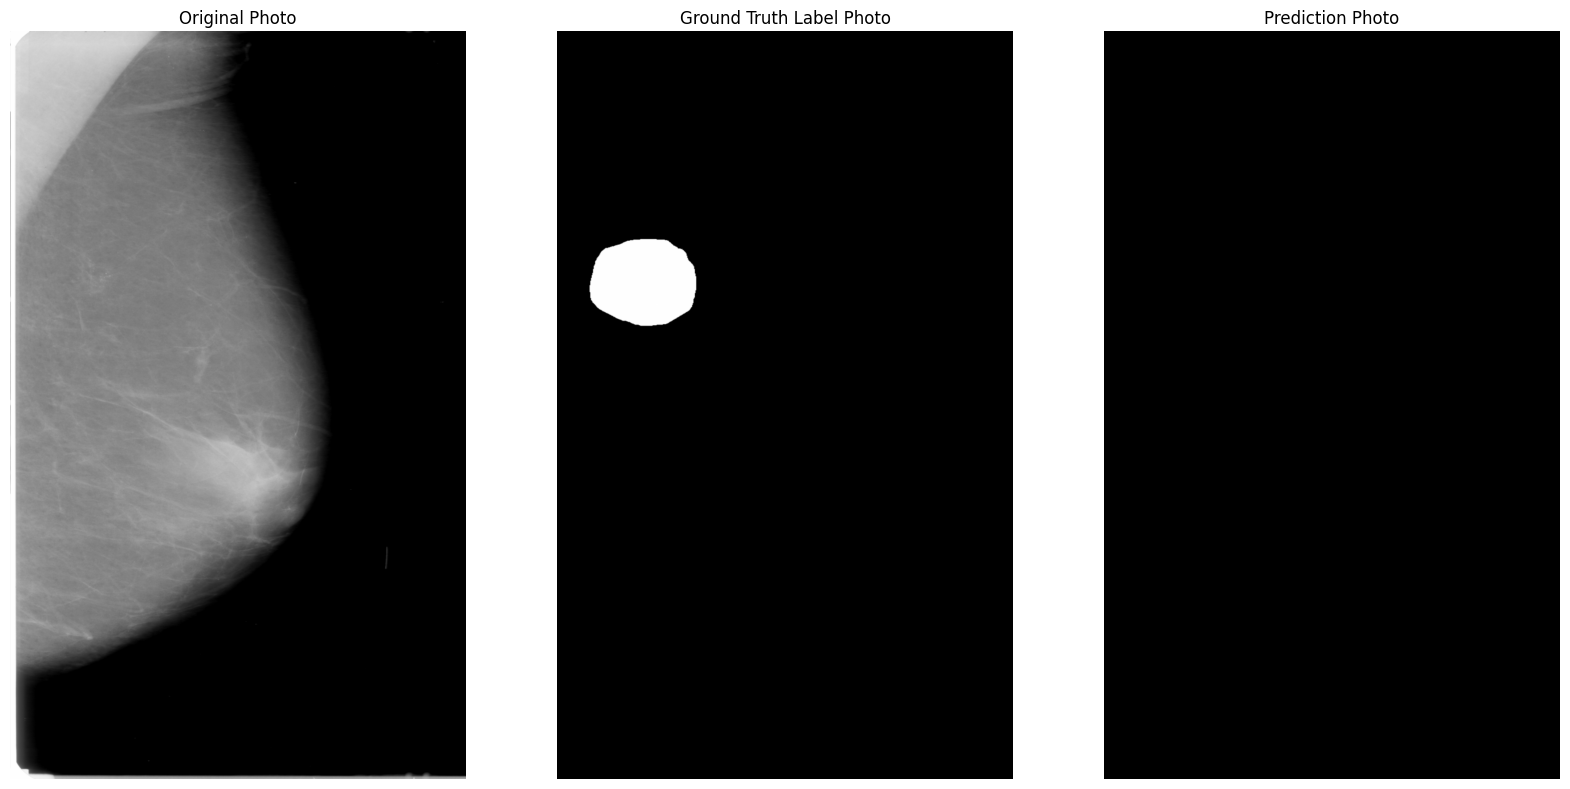

In [ ]:
index = 1
Original_Photo = cv2.imread(test_x[index], cv2.IMREAD_COLOR)
Manual_Label_Photo = cv2.imread(mask_x[index], cv2.IMREAD_COLOR)
ai_x = sorted(glob(os.path.join(save_path, "", "*")))
AI_Label_Photo = cv2.imread(ai_x[index], cv2.IMREAD_COLOR)

# Görüntüleri göster
plt.figure(figsize=(20, 10))

plt.subplot(1, 3, 1)
plt.imshow(Original_Photo)
plt.title("Original Photo")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(Manual_Label_Photo)
plt.title("Ground Truth Label Photo")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(AI_Label_Photo)
plt.title("Prediction Photo")
plt.axis('off')

plt.show()